# What the weather forecast knows about tomorrow

The solar model will read a weather forecast made about two days before the hour it describes. Its two baselines read none: the same slot two days back, and the mean of the same slot over the last seven days. [Notebook 09](09_output_against_clear_sky.ipynb) found where they fail: on cloudy days both miss by 15 to 17% of capacity, because no rule over past output knows what kind of day tomorrow will be. This notebook asks one question before any weather feature or model is built: **does the forecast, as known when we decide, tell what kind of day tomorrow will be?**

Written down before it was run:

| We assumed | What would make us think again |
| --- | --- |
| The forecast separates clear days from cloudy ones well | – |
| A one-line rule, the seven-day mean scaled by how the forecast for tomorrow compares with the forecasts for that week, beats the plain seven-day mean, clearly so on cloudy days | If it doesn't beat it on cloudy and mixed days, the forecast at this range adds too little: look at fresher forecasts before building a model on this one |

Two things are out of scope: which weather variables to use (the backtest decides, with and without each), and the difference between a two-day-old and a one-day-old forecast (four days of the newer kind so far).

The last four months of the backtest, July to October 2026, are held back in section 4: the choice this notebook supports is made on the 16 months before them.

## 0. Setup

**Step.** One query gives every slot of every target day with what DWS knew at its decision time `T` (09:00 the day before): clear-sky output, capacity, the seven-day mean, the same slot two days back, and the forecast radiation. The forecast is MSM's, the model the solar path uses, weighted over the nine points as clear sky is (`dws_point_weights`). The label comes beside it. `ads_ml_day_solar` gives each day's real clearness and its sky: clear, mixed or cloudy. That table uses the 14 days after each day, which is right here: the forecast is judged afterwards, and nothing in it is fed to a rule.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
pd.set_option("display.float_format", "{:,.3f}".format)


def setting(name: str) -> str:
    if value := os.environ.get(name):
        return value
    lines = Path("../.env").read_text().splitlines()
    env = dict(line.split("=", 1) for line in lines if "=" in line and not line.startswith("#"))
    return env[name]


PROJECT = setting("JTF_BIGQUERY_PROJECT")
PREFIX = setting("JTF_DBT_DATASET_PREFIX")
ADS, DWS, DIM = (f"{PROJECT}.{PREFIX}_{layer}" for layer in ("ads", "dws", "dim"))
bq = bigquery.Client(project=PROJECT, location=setting("JTF_BIGQUERY_LOCATION"))


def sql(query: str) -> pd.DataFrame:
    """Run a query in the dev project; print what it scanned and how long it took."""
    job = bq.query(query, job_config=bigquery.QueryJobConfig(use_query_cache=False))
    rows = job.to_dataframe(create_bqstorage_client=False)
    seconds = (job.ended - job.started).total_seconds()
    print(f"[{(job.total_bytes_processed or 0) / 1e6:.1f} MB scanned, {seconds:.0f} s in BigQuery]")
    return rows


# Every slot of every target day: what DWS knew at its decision time (clear sky, capacity, the
# seven-day mean, the same slot two days back, the forecast radiation), and its label
slots = sql(f"""
WITH forecast AS (  -- MSM's radiation at T, weighted over the nine points as clear sky is
  SELECT w.decision_time, w.slot_start, SUM(p.weight * w.ghi_w_m2) AS forecast_ghi,
    ANY_VALUE(w.source) AS source, COUNT(*) AS points
  FROM `{DWS}.dws_weather` AS w
  INNER JOIN `{DWS}.dws_point_weights` AS p USING (decision_time, point)
  WHERE w.model = 'jma_msm'
  GROUP BY w.decision_time, w.slot_start
)
SELECT f.target_day AS day, FORMAT_TIMESTAMP('%H:%M', f.slot_start, 'Asia/Tokyo') AS slot,
  f.capacity_mw, f.clear_sky_mw, f.solar_mean_7d_mw, f.solar_d2_mw, l.label_mw,
  w.forecast_ghi, w.source, w.points, NOT n.is_night AS is_daylight,
  f.clear_sky_mw >= 0.05 * f.capacity_mw AS is_lit
FROM `{DWS}.dws_solar_features` AS f
INNER JOIN forecast AS w USING (decision_time, slot_start)
INNER JOIN `{DIM}.dim_daylight` AS n USING (slot_start)
LEFT JOIN `{ADS}.ads_ml_label_solar` AS l USING (slot_start)
ORDER BY f.slot_start
""")
slots["day"] = pd.to_datetime(slots["day"])
days = sql(f"SELECT * FROM `{ADS}.ads_ml_day_solar` ORDER BY day")
days["day"] = pd.to_datetime(days["day"])
days = days.set_index("day")
print(
    f"{len(slots):,} slots on {slots['day'].nunique():,} target days; forecast rows per slot: "
    f"{slots['points'].min()} to {slots['points'].max()}; days by where the forecast came from: "
    f"{slots.groupby('source')['day'].nunique().to_dict()}"
)
print(
    f"{len(days):,} days with a label for every slot, {int(days['sky'].notna().sum()):,} of them "
    f"grouped: {days['sky'].value_counts().to_dict()}"
)


def grid(column: str) -> pd.DataFrame:
    """One row per day, one column per slot of the day."""
    return slots.pivot(index="day", columns="slot", values=column).asfreq("D")


LIT = grid("is_lit").fillna(False).astype(bool)
FORECAST, CLEAR_SKY, CAPACITY = grid("forecast_ghi"), grid("clear_sky_mw"), grid("capacity_mw")
CLEAR_GHI = CLEAR_SKY / CAPACITY * 1000  # the clear-sky radiation behind clear_sky_mw

[78.3 MB scanned, 1 s in BigQuery]


[0.0 MB scanned, 0 s in BigQuery]
48,384 slots on 1,008 target days; forecast rows per slot: 9 to 9; days by where the forecast came from: {'live': 4, 'previous_runs': 1003, 'single_runs': 1}
1,006 days with a label for every slot, 992 of them grouped: {'clear': 377, 'mixed': 357, 'cloudy': 258}


**What it shows.** 48,384 slots on 1,008 target days, nine forecast rows per slot (one model, nine points). The forecast comes from the history of two-day-old forecasts on 1,003 days, and from the live capture on the last four. 992 days are grouped: 377 clear, 357 mixed, 258 cloudy.

## 1. Forecast against output, day by day

**Step.** For each day, the forecast's radiation over clear-sky radiation across the lit slots, against the day's output over clear-sky output. Each dot is a day, coloured by how it turned out.

,days,correlation,rank_correlation
0,992,0.853,0.878


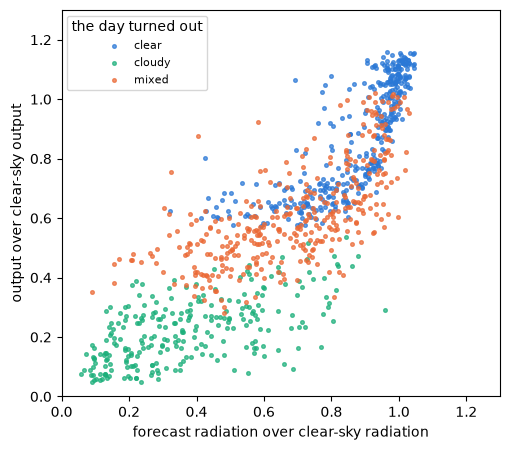

In [2]:
forecast_ratio = (FORECAST.where(LIT).sum(axis=1) / CLEAR_GHI.where(LIT).sum(axis=1)).rename(
    "forecast"
)
both = pd.concat([forecast_ratio, days["day_ratio"].rename("output"), days["sky"]], axis=1).dropna()
fig, ax = plt.subplots(figsize=(5.2, 4.6))
colours = {"clear": "#2a78d6", "mixed": "#eb6834", "cloudy": "#1baf7a"}
for sky, group in both.groupby("sky"):
    ax.scatter(group["forecast"], group["output"], s=7, color=colours[sky], label=sky, alpha=0.7)
ax.set(
    xlabel="forecast radiation over clear-sky radiation",
    ylabel="output over clear-sky output",
    xlim=(0, 1.3),
    ylim=(0, 1.3),
)
ax.legend(title="the day turned out", fontsize=8)
fig.tight_layout()
pd.DataFrame(
    {
        "days": [len(both)],
        "correlation": [both["forecast"].corr(both["output"])],
        "rank_correlation": [both["forecast"].corr(both["output"], method="spearman")],
    }
)

**What it shows.** **Observed:**

- **They move together:** a correlation of 0.85, and 0.88 by rank, over 992 days
- **Cloudy days sit low on both axes, clear days high on both.** Few dots are in the wrong corner
- **The cloud is wide in the middle:** at a forecast ratio of 0.6, output runs from 0.2 to 0.9 of clear sky

Part of that agreement is the season, which both ratios share: output over clear sky runs from 0.72 in summer to 1.19 in winter (notebook 09), whatever the weather. The next step takes the season out of both.

## 2. Clearness against clearness

**Step.** Real clearness is a day's ratio over a clear day's at its time of year (`ads_ml_day_solar`). The same is done to the forecast: its ratio over the 90th percentile of the 29 days around it.

In [3]:
def clearness(ratio: pd.Series) -> pd.Series:
    """A day's ratio over a clear day's at its time of year: the 90th percentile of the 29 days
    around it, as ads_ml_day_solar does for output."""
    return ratio / ratio.asfreq("D").rolling(29, center=True, min_periods=8).quantile(0.9)


both["forecast_clearness"] = clearness(forecast_ratio).reindex(both.index)
both["clearness"] = days["clearness"].reindex(both.index)
both = both.dropna()
print(
    f"correlation of clearness, forecast against real: "
    f"{both['forecast_clearness'].corr(both['clearness']):.3f}; by rank "
    f"{both['forecast_clearness'].corr(both['clearness'], method='spearman'):.3f}; "
    f"{len(both)} days"
)
both[["forecast_clearness", "clearness"]].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T

correlation of clearness, forecast against real: 0.821; by rank 0.810; 992 days


,count,mean,std,min,10%,25%,50%,75%,90%,max
forecast_clearness,992.000,0.746,0.268,0.068,0.305,0.572,0.841,0.968,1.000,1.229
clearness,992.000,0.710,0.292,0.058,0.225,0.488,0.816,0.959,0.999,1.167


**What it shows.** **Observed:**

- **Without the season, still 0.82** (0.81 by rank)
- **The forecast is kinder to dull days than the sky is:** the dullest tenth of days have a real clearness under 0.23, and a forecast clearness under 0.31; the lower quarter, 0.49 against 0.57

**Learned → design:** the forecast orders days well, and on a slightly compressed scale at the dull end. A model can learn a scale; whether the order is right is what matters.

## 3. Does the forecast put a day in the right group?

**Step.** The forecast's clearness cut where the real one is cut (clear from 0.9, cloudy under 0.5), against how each day turned out.

In [4]:
ORDER = ["clear", "mixed", "cloudy"]


def sky_of(values: pd.Series, clear_from: float = 0.9, cloudy_under: float = 0.5) -> pd.Series:
    labels = np.select([values >= clear_from, values < cloudy_under], ["clear", "cloudy"], "mixed")
    return pd.Series(pd.Categorical(labels, ORDER), index=values.index)


both["forecast_sky"] = sky_of(both["forecast_clearness"])
both["sky"] = pd.Categorical(both["sky"], ORDER)
table = pd.crosstab(both["sky"], both["forecast_sky"], margins=True)
table.index.name, table.columns.name = "the day turned out", "the forecast said"
display(table)
backwards = (both["sky"].eq("clear") & both["forecast_sky"].eq("cloudy")) | (
    both["sky"].eq("cloudy") & both["forecast_sky"].eq("clear")
)
print(
    f"same group: {(both['sky'] == both['forecast_sky']).mean():.1%} of days; "
    f"clear called cloudy or cloudy called clear: {int(backwards.sum())} days"
)

the forecast said,clear,mixed,cloudy,All
the day turned out,,,,
clear,306,70,1,377
mixed,114,211,32,357
cloudy,4,88,166,258
All,424,369,199,992


same group: 68.9% of days; clear called cloudy or cloudy called clear: 5 days


**What it shows.** **Observed:**

- **69% of days land in the right group,** and when it is wrong it is wrong by one step: only 5 days of 992 are clear called cloudy or cloudy called clear
- **The forecast calls too many days clear and too few cloudy:** 424 clear against 377, and 199 cloudy against 258. That is section 2's compressed scale, cut at the real scale's boundaries

So some of the misses may be the cuts, not the forecast. A second try moves the cuts.

**Step.** Cuts on the forecast's own scale that give the same share of clear and of cloudy days as there really were.

In [5]:
shares = both["sky"].value_counts(normalize=True)
clear_from = both["forecast_clearness"].quantile(1 - shares["clear"])
cloudy_under = both["forecast_clearness"].quantile(shares["cloudy"])
both["forecast_sky_matched"] = sky_of(both["forecast_clearness"], clear_from, cloudy_under)
print(
    f"cuts on the forecast's scale that give the real shares: clear from {clear_from:.3f}, "
    f"cloudy under {cloudy_under:.3f}"
)
table = pd.crosstab(both["sky"], both["forecast_sky_matched"], margins=True)
table.index.name, table.columns.name = "the day turned out", "the forecast said"
display(table)
right = both["sky"] == both["forecast_sky_matched"]
recall = right.groupby(both["sky"], observed=True).mean()
print(
    f"same group: {right.mean():.1%} of days; of the days that turned out clear "
    f"{recall['clear']:.1%}, mixed {recall['mixed']:.1%}, cloudy {recall['cloudy']:.1%}"
)

cuts on the forecast's scale that give the real shares: clear from 0.924, cloudy under 0.583


the forecast said,clear,mixed,cloudy,All
the day turned out,,,,
clear,285,89,3,377
mixed,90,198,69,357
cloudy,2,70,186,258
All,377,357,258,992


same group: 67.4% of days; of the days that turned out clear 75.6%, mixed 55.5%, cloudy 72.1%


**What it shows.** **Observed:**

- **The cuts move to 0.924 and 0.583, and the agreement doesn't improve:** 67% of days in the right group, against 69%
- **Clear and cloudy days are called right about three times in four** (76% and 72%); mixed days about half the time (56%)

**Learned → design:** the misses were not the cuts. They are days near a boundary and mixed days, which are the hardest to call. The forecast almost never gets a day backwards.

**Step.** The same by season, with the matched cuts: the rainy season and winter may differ.

In [6]:
season = days["season"].reindex(both.index)
by_season = pd.DataFrame(
    {
        "days": both.groupby(season).size(),
        "rank_correlation": both.groupby(season)[["forecast_clearness", "clearness"]].apply(
            lambda g: g["forecast_clearness"].corr(g["clearness"], method="spearman")
        ),
        "same_group": right.groupby(season).mean(),
        "cloudy_days": (both["sky"] == "cloudy").groupby(season).sum(),
        "cloudy_days_called_cloudy": (
            both["sky"].eq("cloudy") & both["forecast_sky_matched"].eq("cloudy")
        )
        .groupby(season)
        .sum(),
    }
).reindex(["winter", "spring", "summer", "autumn"])
by_season["share_called"] = by_season["cloudy_days_called_cloudy"] / by_season["cloudy_days"]
by_season

,days,rank_correlation,same_group,cloudy_days,cloudy_days_called_cloudy,share_called
season,,,,,,
winter,193,0.689,0.710,22,14,0.636
spring,276,0.881,0.688,88,62,0.705
summer,276,0.745,0.620,63,46,0.730
autumn,247,0.827,0.692,85,64,0.753


**What it shows.** **Observed:**

- **Spring and autumn are called best** (rank correlation 0.88 and 0.83), summer and winter less well (0.75 and 0.69)
- **Winter has little to tell apart:** 22 cloudy days of 193
- **Cloudy days are called cloudy 64 to 75% of the time in every season**

**Learned → design:** no season where the forecast fails. Summer, with its rainy weeks, is the weakest of the seasons that have many cloudy days.

## 4. The practical test: a one-line rule

**Step.** Agreement in groups is not yet a better forecast of output. The test set before the run: take the seven-day mean and scale it by how the forecast for the target slot compares with the forecasts for the same slot on the seven days the mean was taken over. Everything in it is known at `T`. Beside it:

- the same with one scaling per day, not per slot;
- the two baselines;
- what the seven-day mean would give if scaled by the day's real change in clearness. Nobody can know that at `T`: it shows how far a perfect call of the kind of day would go.

Scored as the backtest scores: mean absolute error on daylight slots, as a share of capacity at `T`. March 2025 to June 2026; the four months after are held back.

In [7]:
LABEL, MEAN_7D, D2 = grid("label_mw"), grid("solar_mean_7d_mw"), grid("solar_d2_mw")
week = pd.concat([FORECAST.shift(back) for back in range(2, 9)]).groupby(level=0).mean()
# The forecast for the target slot over the forecasts for the same slot on the seven days the
# mean was taken over: all known at T
change = (FORECAST / week).where((week >= 20) & LIT)
by_slot = (MEAN_7D * change).fillna(MEAN_7D)
week_days = pd.concat([forecast_ratio.shift(back) for back in range(2, 9)], axis=1).mean(axis=1)
by_day = MEAN_7D.mul(forecast_ratio / week_days, axis=0).fillna(MEAN_7D)
real_week = pd.concat([days["day_ratio"].shift(back) for back in range(2, 9)], axis=1).mean(axis=1)
perfect = MEAN_7D.mul(
    days["day_ratio"].reindex(MEAN_7D.index) / real_week.reindex(MEAN_7D.index), axis=0
)

CANDIDATES = {
    "same slot two days back": D2,
    "seven-day mean": MEAN_7D,
    "mean x forecast change, per slot": by_slot,
    "mean x forecast change, per day": by_day,
    "mean x the day's real change (not knowable)": perfect,
}
FIRST, LAST = "2025-03-01", "2026-06-30"  # July to October 2026 are held back
scored = grid("is_daylight").fillna(False).astype(bool) & LABEL.notna()
scored = scored.loc[FIRST:LAST]
errors = {
    name: ((frame - LABEL) / CAPACITY).loc[FIRST:LAST].where(scored).stack()
    for name, frame in CANDIDATES.items()
}
errors = pd.DataFrame(errors).dropna()
day_of = errors.index.get_level_values("day")
scores = pd.DataFrame({"slots": errors.count(), "mae": errors.abs().mean(), "bias": errors.mean()})
scores["skill_over_seven_day_mean"] = 1 - scores["mae"] / scores.loc["seven-day mean", "mae"]
print(f"{day_of.nunique()} target days, {FIRST} to {LAST}")
scores

487 target days, 2025-03-01 to 2026-06-30


,slots,mae,bias,skill_over_seven_day_mean
same slot two days back,12652,0.126,-0.002,-0.202
seven-day mean,12652,0.105,0.002,0.000
"mean x forecast change, per slot",12652,0.061,-0.000,0.423
"mean x forecast change, per day",12652,0.061,-0.002,0.415
mean x the day's real change (not knowable),12652,0.029,-0.002,0.726


**What it shows.** **Observed**, on 12,652 daylight slots of 487 target days:

- **The rule misses by 6.1% of capacity, the seven-day mean by 10.5%:** a skill of 0.42 over the stronger baseline
- **Per slot or per day makes no difference** (6.1% both)
- **A perfect call of the day would give 2.9%**

A gain this large from one line needs a second look before it is believed. An input that looks too good is usually a leak: a forecast made after `T`, read by mistake.

**Step.** Where each target day's forecast came from, and whether any of it was captured or run after `T`.

In [8]:
sql(f"""
SELECT source, lead_days, COUNT(DISTINCT target_day) AS target_days,
  COUNTIF(captured_at > decision_time) AS captured_after_t,
  COUNTIF(run_time >= decision_time) AS run_after_t,
  MIN(TIMESTAMP_DIFF(slot_start, decision_time, HOUR)) AS fewest_hours_from_t_to_the_slot,
  MAX(TIMESTAMP_DIFF(slot_start, decision_time, HOUR)) AS most_hours_from_t_to_the_slot
FROM `{DWS}.dws_weather`
WHERE model = 'jma_msm'
GROUP BY source, lead_days
ORDER BY target_days DESC
""")

[75.3 MB scanned, 0 s in BigQuery]


,source,lead_days,target_days,captured_after_t,run_after_t,fewest_hours_from_t_to_the_slot,most_hours_from_t_to_the_slot
0,previous_runs,2,1003,0,0,15,38
1,live,<NA>,4,0,0,15,38
2,previous_runs,<NA>,4,0,0,15,38
3,single_runs,<NA>,1,0,0,15,38


**What it shows.** **Observed:**

- **1,003 target days read the history at a lead of two days:** the forecast issued two days before each hour it describes. For a slot of day D that is some time on D−2, and `T` is 09:00 on D−1, so every such value was issued before `T`
- **Four of those days have rows with no lead:** 10 to 18 slots where MSM has no value at all, filled from ECMWF at the same lead ([notebook 04](04_ods_to_dwd.ipynb), section 3.6). `dws_weather` keeps only lead 2 from the history, so the values are right; the row has no MSM lead to carry
- **No row was captured or run after its decision time**

**Learned → design:** not a leak. And the size is the usual one: a forecast a day or two old for the whole Tokyo area is in the range that area forecasts reach, where the baselines only repeat the recent past. What the forecasts of one day and of the same day's morning would add is the leak scenario's subject, later.

**Step.** How far the forecast goes towards a perfect call of the day; then the rule by kind of day, the error and the bias; then month by month.

In [9]:
mean, rule, best = (
    scores.loc[name, "mae"]
    for name in (
        "seven-day mean",
        "mean x forecast change, per slot",
        "mean x the day's real change (not knowable)",
    )
)
print(
    f"from the seven-day mean ({mean:.3f}) to knowing the day's real change ({best:.3f}): "
    f"the forecast covers {(mean - rule) / (mean - best):.0%} of the way ({rule:.3f})"
)

from the seven-day mean (0.105) to knowing the day's real change (0.029): the forecast covers 58% of the way (0.061)


In [10]:
sky_of_day = pd.Series(
    pd.Categorical(days["sky"].reindex(day_of).to_numpy(), ORDER), index=errors.index
)
by_sky = errors.abs().groupby(sky_of_day, observed=True).mean()
by_sky.insert(
    0, "days", pd.Series(day_of, index=errors.index).groupby(sky_of_day, observed=True).nunique()
)
display(by_sky.T)
bias = errors.groupby(sky_of_day, observed=True).mean()
bias.T

,clear,mixed,cloudy
days,190.000,174.000,123.000
same slot two days back,0.096,0.122,0.178
seven-day mean,0.097,0.069,0.168
"mean x forecast change, per slot",0.050,0.063,0.073
"mean x forecast change, per day",0.053,0.064,0.071
mean x the day's real change (not knowable),0.022,0.038,0.025


,clear,mixed,cloudy
same slot two days back,-0.085,-0.026,0.156
seven-day mean,-0.095,-0.014,0.166
"mean x forecast change, per slot",-0.029,-0.004,0.048
"mean x forecast change, per day",-0.032,-0.006,0.047
mean x the day's real change (not knowable),-0.003,-0.002,-0.001


In [11]:
fold = pd.Series(day_of.to_period("M"), index=errors.index)
by_fold = errors.abs().groupby(fold).mean()
rule, mean = by_fold["mean x forecast change, per slot"], by_fold["seven-day mean"]
print(
    f"months where the rule beats the seven-day mean: {int((rule < mean).sum())} of "
    f"{len(by_fold)}; largest gain {float((mean - rule).max()):.3f}, "
    f"smallest {float((mean - rule).min()):.3f}"
)
by_fold[["seven-day mean", "mean x forecast change, per slot"]].T.round(3)

months where the rule beats the seven-day mean: 16 of 16; largest gain 0.080, smallest 0.012


day,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06
seven-day mean,0.147,0.135,0.113,0.124,0.073,0.079,0.087,0.111,0.082,0.086,0.053,0.112,0.121,0.125,0.107,0.115
"mean x forecast change, per slot",0.076,0.055,0.060,0.070,0.061,0.053,0.051,0.069,0.061,0.039,0.035,0.066,0.076,0.057,0.059,0.074


**What it shows.** **Observed:**

- **The forecast covers 58% of the way** from the seven-day mean to a perfect call of the day
- **Cloudy days: 7.3% of capacity, against 16.8%.** The baselines' bias there, 16 to 17 points too high, falls to 5
- **Clear days: 5.0%, against 9.7%,** the bias from 9.5 points too low to 3
- **Mixed days: 6.3%, against 6.9%:** the seven-day mean was already good there
- **Better in all 16 months,** by 1.2 to 8.0 points of capacity

**Learned → design:** the test set before the run is passed, on cloudy and on mixed days, and by far the most on cloudy ones. The weather inputs are worth building.

## What this exploration made known

| We assumed | We found | So |
| --- | --- | --- |
| The forecast separates clear days from cloudy ones well | Forecast clearness follows real clearness at 0.82. It puts 69% of days in the right group and gets 5 of 992 backwards; mixed days are the hardest (sections 1 to 3) | It does. A model reads the forecast to know the kind of day |
| The forecast's scale is the sky's | It is compressed at the dull end: the dullest tenth of days are under 0.31 on the forecast and under 0.23 in fact. Moving the cuts to match changes nothing (sections 2, 3) | Nothing to correct by hand: a model learns the scale |
| A one-line rule with the forecast beats the seven-day mean, clearly so on cloudy days | 6.1% of capacity against 10.5%, a skill of 0.42, in all 16 months; on cloudy days 7.3% against 16.8% (section 4) | **The weather inputs and the model are worth building.** The criterion set before the run is met |
| (Not asked beforehand) Whether a gain that large is a leak | Every forecast value was issued before its decision time; none captured or run after (section 4) | Not a leak |
| (Not asked beforehand) What the model has to beat | The rule itself: the seven-day mean scaled by the forecast's change | **The model's bar is 6.1%, not 10.5%.** The rule becomes a third baseline, so a model that only rediscovers it shows no skill |
| (Not asked beforehand) How much is left | A perfect call of the day would give 2.9%; the forecast covers 58% of the way | The rest is forecast error and what happens within a day: the room a model and fresher forecasts have |

## Still open

| What | Why it can't be known yet | When |
| --- | --- | --- |
| What a one-day-old forecast adds over a two-day-old one | History holds the two-day-old kind; the live capture, about a day old, covers four target days | After some weeks of live capture |
| Whether the held-back months, July to October 2026, agree | They are looked at once, when the model is chosen | The model's final backtest |
| Which variables carry the signal beyond radiation | Out of scope here | The backtest, with and without each |

## Where the sources and the data disagree

| Where | Says | We found | Handled by |
| --- | --- | --- | --- |
| [Phase-1 plan](../docs/phase1/README.md#model-and-evaluation), Baselines | Two baselines: persistence and the seven-day mean | A one-line rule with the forecast is far stronger than both (section 4) | The rule joins the baselines, and skill is reported against it |
| `dws_weather`, column `lead_days` | The lead of the forecast a row holds | Empty on slots filled whole from another model, on four target days (section 4) | The values are at lead 2; the column is filled from the model that gave the value when the weather inputs are built |

## Sources

| Page | Supports |
| --- | --- |
| [Notebook 09](09_output_against_clear_sky.ipynb), sections 5 to 7 | The baselines' errors by kind of day; clearness; forecast radiation on the right slots |
| [Notebook 04](04_ods_to_dwd.ipynb), sections 3.2 and 3.4 | Which forecast a decision time can use: the history at a lead of two days, the live capture |
| `warehouse/dbt/models/ads/ads_ml_day_solar.sql` | A day's clearness and sky |